# Avance 2 · Ingeniería de características
## Avocado Insights | Oferta municipal para la planeación logística

**Equipo 4 · TC5035.10 · 11 de octubre de 2026**  
**Profesor:** Dr. Raúl Valente Ramírez Velarde  
**Sponsor:** Dr. Jorge Antonio Ascencio Gutiérrez

| Integrante | Matrícula |
|---|---|
| José Roberto Sánchez Rocha | A00903762 |
| Josué Águila Ramos | A01796400 |
| Roberto Perézcano Hernández | A01730502 |

**Propósito.** Convertir el historial agrícola en atributos trazables de capacidad productiva,
productividad, variación y contexto territorial. Se preparan dos representaciones para la siguiente
fase de modelado: una interpretable y otra compacta con PCA. El componente de oferta puede apoyar
la planeación logística; estos datos no permiten identificar rutas óptimas ni calcular emisiones.

**Resultado verificable.** La libreta se ejecuta de principio a fin, conserva el dato original,
documenta cada ajuste y exporta matrices, diccionario, parámetros y evidencia. Las conclusiones
se calculan con los resultados obtenidos; una distribución menos sesgada no se presenta como
prueba de mayor capacidad predictiva.

### Guía de lectura y correspondencia con la rúbrica

| Criterio | Evidencia ejecutada | Sección |
|---|---|---|
| Construcción · 30 puntos | Rezagos por calendario, memoria de tres años, proporciones, cambios, categorías y discretización; diccionario y fundamento | 2–5 |
| Normalización · 30 puntos | Comparación identidad/log1p/Yeo–Johnson; imputación con indicadores; estandarización ajustada en entrenamiento | 6–7 |
| Selección / extracción · 30 puntos | Varianza nula, redundancia por Spearman, indicadores repetidos, sensibilidad del umbral, PCA y análisis de cargas | 8–9 |
| Conclusiones · 10 puntos | Resultados, calidad, límites, criterios de aceptación y transición a modelado dentro de CRISP-ML(Q) | 12 |

**Cómo reproducir.** Desde la raíz del repositorio, instalar `requirements_avance2.txt`, abrir
`notebooks/Avance2.Equipo4.ipynb` y ejecutar *Restart Kernel and Run All*. La libreta requiere
`src/fe_avance2.py` y `data/raw/siap_produccion.csv`; no necesita descargas de datos ni servicios externos
durante el análisis. Los archivos derivados se escriben bajo `data/avance2/` y `resultados/avance2/`.

In [1]:
from pathlib import Path
import sys, json, hashlib, platform, time, warnings
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, mean_squared_log_error
import joblib
from IPython.display import display, Markdown

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'src/fe_avance2.py').exists() and (p/'data/raw/siap_produccion.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Abrir la libreta dentro del paquete completo; faltan src/ o data/raw/.')
sys.path.insert(0,str(ROOT/'src'))
from fe_avance2 import (read_raw, prepare_panel, build_features, FeaturePreparation,
                       feature_dictionary, NUMERIC, CATEGORICAL, KEY, ADDITIVE, RAW_SHA256)
OUT, DATA = ROOT/'resultados/avance2', ROOT/'data/avance2'
OUT.mkdir(parents=True,exist_ok=True); DATA.mkdir(parents=True,exist_ok=True)
sns.set_theme(style='whitegrid',context='notebook',palette=['#177B60','#EAAD43','#2C5D86','#9A659E'])
plt.rcParams.update({'figure.dpi':115,'savefig.dpi':160,'axes.titleweight':'bold','axes.spines.top':False,'axes.spines.right':False})
pd.set_option('display.max_rows',80)
pd.set_option('display.max_columns',14)
pd.set_option('display.max_colwidth',None)
pd.set_option('display.float_format',lambda x:f'{x:,.4f}')

def table(df,name,index=False):
    df.to_csv(OUT/(name+'.csv'),index=index)
    display(df)

def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT/(name+'.png'),bbox_inches='tight')
    plt.show()

versions={'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,
          'scipy':scipy.__version__,'scikit-learn':sklearn.__version__,
          'matplotlib':matplotlib.__version__,'seaborn':sns.__version__,'joblib':joblib.__version__}
print('Entorno de ejecución:',json.dumps(versions,ensure_ascii=False))
print('Motor determinista: PCA SVD completa; sin muestreo aleatorio en los ajustes.')

Entorno de ejecución: {"python": "3.12.14", "numpy": "2.3.5", "pandas": "2.2.3", "scipy": "1.17.0", "scikit-learn": "1.8.0", "matplotlib": "3.10.8", "seaborn": "0.13.2", "joblib": "1.5.3"}
Motor determinista: PCA SVD completa; sin muestreo aleatorio en los ajustes.


### 1. Continuidad, procedencia y respuesta a la retroalimentación

El doctor pidió precisar qué se hará con las numerosas ausencias de 1980–2002. Se verifica si son
datos perdidos de una observación municipal o un cambio en el nivel geográfico. **Un municipio
no se puede inferir a partir de un total estatal.** Se conservará esa historia en un archivo aparte,
con posibilidad de análisis estatal independiente; no se repartirá entre municipios ni se rellenarán
nombres con la moda. Así se evita multiplicar totales y crear ubicaciones ficticias.

La base es exactamente la del Avance 1 publicado en el repositorio, fijada al commit
`79de83046351f162cd0024cdac3424bfc1fc304a`. Contiene cierres agrícolas atribuidos a SIAP/DGSIAP,
recuperados originalmente mediante el espejo público `lapanquecita/aguacate` porque la descarga
oficial falló. Se conserva `data/proveniencia.json`, la licencia del espejo y el SHA-256 de los bytes.
La validación parcial de 2023 hecha en el Avance 1 no certifica todo el conjunto ni su historial de revisiones.
El portal oficial sigue siendo la referencia de origen (Secretaría de Agricultura y Desarrollo Rural, s. f.; Montse [lapanquecita], 2026; Equipo 4, 2026).

Otra decisión heredada es **poner 2024 en cuarentena**: presenta claves administrativas repetidas
y falta información para determinar si son duplicados o una desagregación no representada.
Se guarda completo para conciliación con el proveedor. Ni sumar todo ni eliminar filas por coincidencia
de clave resuelve esa ambigüedad. Los años restantes se agregan por municipio y año, sumando solo
superficies, volumen y valor; rendimiento y precio se recalculan como cocientes de totales.

CVE_MUN=999 en 1980–2002: 981 de 981
2024: filas en claves repetidas: 263 | repeticiones adicionales: 137


,conjunto,filas,periodo,decision
0,Fuente completa,15474,1980–2025,Conservar intacta; verificar SHA-256
1,Historia estatal,981,1980–2002,Conservar aparte; no imputar municipios
2,Cuarentena,900,2024,Conciliar claves antes de usar
3,Registros administrativos elegibles,13593,2003–2023 y 2025,Agregar magnitudes aditivas
4,Panel municipal anual,11665,2003–2023 y 2025,Base para construir historia por calendario


,AÑO,MUNICIPIO,CVE_DDR,DISTRITO,CVE_CADER,CADER
0,1980,1.0000,1.0000,1.0000,1.0000,1.0000
1,1981,1.0000,1.0000,1.0000,1.0000,1.0000
2,1982,1.0000,1.0000,1.0000,1.0000,1.0000
3,1983,1.0000,1.0000,1.0000,1.0000,1.0000
4,1984,1.0000,1.0000,1.0000,1.0000,1.0000
5,1985,1.0000,1.0000,1.0000,1.0000,1.0000
6,1986,1.0000,1.0000,1.0000,1.0000,1.0000
7,1987,1.0000,1.0000,1.0000,1.0000,1.0000
8,1988,1.0000,1.0000,1.0000,1.0000,1.0000
9,1989,1.0000,1.0000,1.0000,1.0000,1.0000


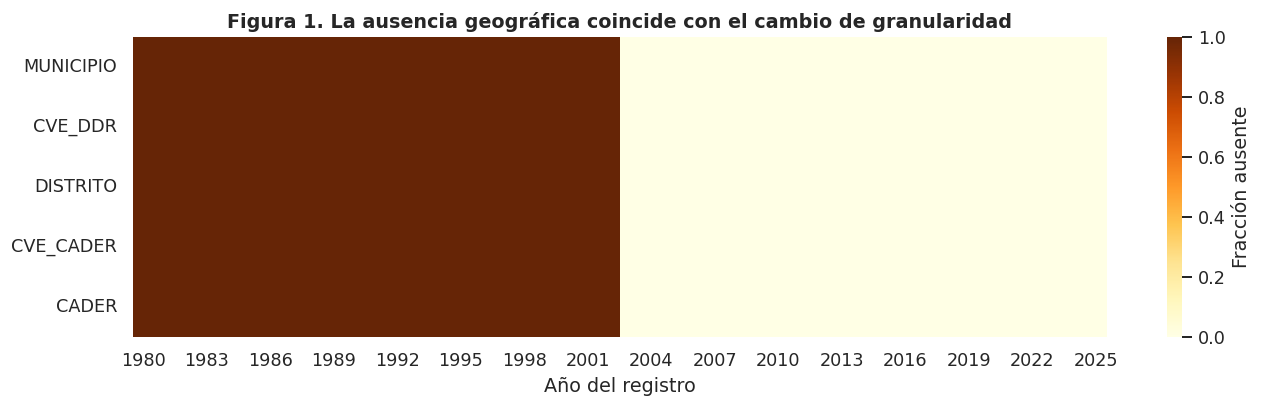

In [2]:
raw = read_raw(ROOT/'data/raw/siap_produccion.csv')
panel, historia_estatal, cuarentena = prepare_panel(raw)
historia_estatal.to_csv(DATA/'historia_estatal_1980_2002.csv',index=False)
cuarentena.to_csv(DATA/'cuarentena_2024.csv',index=False)
panel.to_csv(DATA/'panel_municipal.csv',index=False)

audit = pd.DataFrame([
    ['Fuente completa',len(raw),'1980–2025','Conservar intacta; verificar SHA-256'],
    ['Historia estatal',len(historia_estatal),'1980–2002','Conservar aparte; no imputar municipios'],
    ['Cuarentena',len(cuarentena),'2024','Conciliar claves antes de usar'],
    ['Registros administrativos elegibles',len(raw)-len(historia_estatal)-len(cuarentena),'2003–2023 y 2025','Agregar magnitudes aditivas'],
    ['Panel municipal anual',len(panel),'2003–2023 y 2025','Base para construir historia por calendario']
],columns=['conjunto','filas','periodo','decision'])
table(audit,'01_trazabilidad_filas')
cols_geo=['MUNICIPIO','CVE_DDR','DISTRITO','CVE_CADER','CADER']
missing_by_year=raw.groupby('AÑO')[cols_geo].agg(lambda s:s.isna().mean())
print('CVE_MUN=999 en 1980–2002:',int(historia_estatal.CVE_MUN.eq(999).sum()),'de',len(historia_estatal))
print('2024: filas en claves repetidas:',int(cuarentena.duplicated(KEY,False).sum()),
      '| repeticiones adicionales:',int(cuarentena.duplicated(KEY).sum()))
table(missing_by_year.reset_index(),'02_ausencia_geografica_por_anio')
fig,ax=plt.subplots(figsize=(12,3.7))
sns.heatmap(missing_by_year.T,cmap='YlOrBr',vmin=0,vmax=1,xticklabels=3,
            cbar_kws={'label':'Fracción ausente'},ax=ax)
ax.set(xlabel='Año del registro',ylabel='',title='Figura 1. La ausencia geográfica coincide con el cambio de granularidad')
savefig('fig01_ausencias_geograficas')

**Interpretación.** La continuidad de los cinco campos geográficos ausentes y el código municipal
999 identifica un bloque estatal. Se preservan sus 981 observaciones; la base municipal comienza
en 2003. Esto es una separación por unidad de observación, no una imputación ni una eliminación
general de todas las filas que contienen algún nulo. Las ausencias posteriores de rendimiento o
precio requieren un tratamiento distinto: pueden ser cocientes indefinidos cuando no hay cosecha.

Los años estatales antiguos tampoco se mezclan para construir variables monetarias: el archivo
no contiene una serie deflactada ni documentación suficiente para armonizar todo el periodo.
En la cohorte municipal el valor y el precio se interpretan como **pesos nominales**, sin atribuir
a sus cambios un efecto real de poder adquisitivo.

### 2. Contrato del problema y de disponibilidad temporal

| Elemento | Definición operativa |
|---|---|
| Unidad | Municipio identificado por `CVE_ENT` + `CVE_MUN`, en un año calendario |
| Objetivo para la siguiente fase | `produccion_t`: volumen anual municipal de aguacate, en toneladas |
| Utilidad | Aproximar la oferta territorial para dimensionar necesidades de acopio y transporte |
| Historia disponible en el escenario | Mediciones de **t−2 o anteriores**; el año objetivo se conoce por calendario |
| Rezagos | Unión sobre calendario completo por municipio; nunca desplazamiento sobre filas discontinuas |
| Ceros | Un cero reportado se conserva; una observación inexistente sigue siendo ausente |
| Exclusiones del vector X | Producción, precio, área y valor del mismo año objetivo; identidad municipal; nombres; claves administrativas constantes |
| Alcance geográfico | Municipios observados con producción registrada dos años antes; se informa la cobertura de casos sin historia |

Se usa t−2 como **supuesto conservador de trabajo** porque la fuente es un cierre anual y no un
flujo en tiempo real. No se afirma haber verificado la fecha de publicación de cada dato. El CSV
es una instantánea revisada, sin versiones históricas ni sellos de disponibilidad: evita fuga por
fecha de medición, pero no permite demostrar un backtest estrictamente *as-of*.
El sponsor deberá validar ese calendario antes de una aplicación operativa.

El pronóstico aquí definido es anual y a nivel municipal; no es mensual, de exportaciones ni de
CO₂. No se incorporan INEGI/RNC o distancias sin una unión geográfica y temporal verificable.
`CADER` es una referencia administrativa y no se interpreta como centro de acopio.

,particion,observados,elegibles,volumen_observado_t,sin_historia_lag2,cobertura_filas_pct,volumen_elegible_t,cobertura_volumen_pct
0,train,4373,3930,"11,856,432.3000",443,89.8697,"11,825,335.7800",99.7377
1,validacion,1869,1734,"6,879,400.6000",135,92.7769,"6,867,492.9400",99.8269
2,reserva_2023,648,637,"2,973,344.4200",11,98.3025,"2,971,609.3500",99.9416
3,aplicacion_2025,655,647,"2,792,481.0500",8,98.7786,"2,789,586.6200",99.8963


,uso,años_objetivo,regla
0,Entrenamiento,2007–2015,"Ajustar imputación, transformaciones, codificación, filtros y PCA"
1,Separación temporal,2016–2017,No se usan como objetivos para ajuste ni evaluación
2,Validación,2018–2020,Comparación instrumental de representaciones; sin reajuste del preprocesador
3,Separación temporal,2021–2022,No se usan como objetivos; sí como historia cuando sea disponible
4,Reserva interna,2023,Solo transformación y comprobaciones de integridad; sin puntuación predictiva
5,Cuarentena,2024,Sin uso hasta resolver granularidad
6,Aplicación retrospectiva,2025,Demostrar que el pipeline transforma casos posteriores usando historia hasta 2023


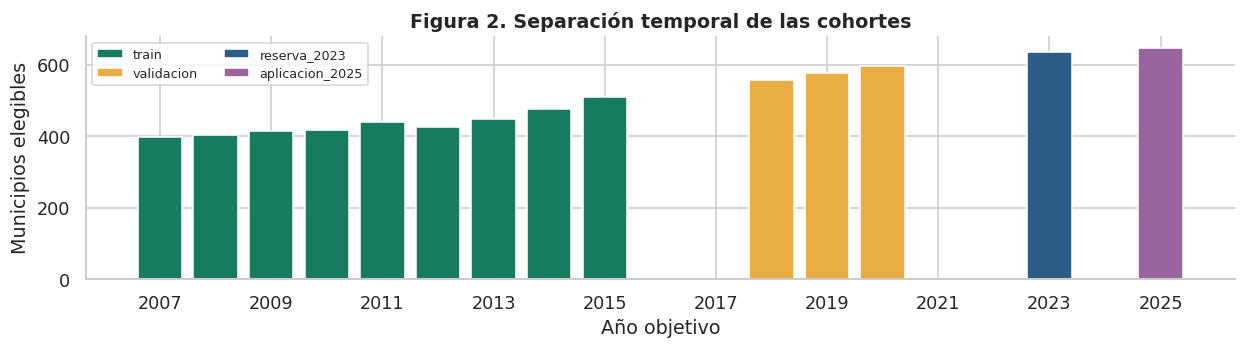

In [3]:
features = build_features(panel)
cohort = features.loc[features.elegible].copy()
train = cohort.loc[cohort.particion.eq('train')].copy()
valid = cohort.loc[cohort.particion.eq('validacion')].copy()
reserve = cohort.loc[cohort.particion.eq('reserva_2023')].copy()
application = cohort.loc[cohort.particion.eq('aplicacion_2025')].copy()
splits={'train':train,'validacion':valid,'reserva_2023':reserve,'aplicacion_2025':application}

coverage=(features.loc[features.observado_objetivo & features.particion.ne('fuera_de_particion')]
          .groupby('particion',sort=False)
          .agg(observados=('produccion_t','size'),elegibles=('elegible','sum'),
               volumen_observado_t=('produccion_t','sum')))
coverage['sin_historia_lag2']=coverage.observados-coverage.elegibles
coverage['cobertura_filas_pct']=100*coverage.elegibles/coverage.observados
coverage['volumen_elegible_t']=cohort.groupby('particion').produccion_t.sum()
coverage['cobertura_volumen_pct']=100*coverage.volumen_elegible_t/coverage.volumen_observado_t
table(coverage.reset_index(),'03_cobertura_cohortes')

partition=pd.DataFrame([
    ['Entrenamiento','2007–2015','Ajustar imputación, transformaciones, codificación, filtros y PCA'],
    ['Separación temporal','2016–2017','No se usan como objetivos para ajuste ni evaluación'],
    ['Validación','2018–2020','Comparación instrumental de representaciones; sin reajuste del preprocesador'],
    ['Separación temporal','2021–2022','No se usan como objetivos; sí como historia cuando sea disponible'],
    ['Reserva interna','2023','Solo transformación y comprobaciones de integridad; sin puntuación predictiva'],
    ['Cuarentena','2024','Sin uso hasta resolver granularidad'],
    ['Aplicación retrospectiva','2025','Demostrar que el pipeline transforma casos posteriores usando historia hasta 2023']
],columns=['uso','años_objetivo','regla'])
table(partition,'04_particiones_temporales')
fig,ax=plt.subplots(figsize=(11,3.2))
colors={'train':'#177B60','validacion':'#EAAD43','reserva_2023':'#2C5D86','aplicacion_2025':'#9A659E'}
for name,d in splits.items():
    counts=d.groupby('anio').size()
    ax.bar(counts.index,counts.values,color=colors[name],label=name)
ax.set(xlabel='Año objetivo',ylabel='Municipios elegibles',title='Figura 2. Separación temporal de las cohortes')
ax.set_xticks(range(2007,2026,2));ax.legend(ncol=2,loc='upper left',fontsize=8)
savefig('fig02_particiones')

La separación temporal deja margen entre el ajuste y el inicio de la validación; no se hace una
partición aleatoria de filas. Los años excluidos **como etiquetas de entrenamiento** pueden formar
parte de la historia de una predicción posterior si cumplen t−2. Es distinto usar un dato pasado
como entrada que reajustar un algoritmo con su etiqueta (The scikit-learn developers, s. f.-a).

La reserva de 2023 es interna: el Avance 1 ya exploró el conjunto completo. Por ello no se presenta
como una prueba totalmente desconocida. La aplicación de 2025 también es retrospectiva: su
producción ya aparece en la fuente. La evaluación verdaderamente prospectiva queda pendiente.
Los municipios sin observación t−2 se reportan aparte y requieren una política de inicio sin
historia; no se oculta esa limitación rellenando su producción.

### 3. Construcción de atributos con sentido de dominio

Se recomputan los indicadores a partir de totales municipales para evitar promediar rendimientos
o precios de parcelas/modalidades con distinto tamaño. `rendimiento = toneladas / ha cosechadas`
y `precio = valor / toneladas`; cuando el denominador es cero, el cociente permanece ausente.

La memoria abarca t−2, t−3 y t−4. Media, desviación estándar, mínimo y máximo requieren al menos
dos observaciones; `n_observaciones_3` hace visible la cobertura efectiva. El coeficiente de
variación exige media positiva. Los cambios `log1p(x[t−2]) − log1p(x[t−3])` admiten cero y moderan
escalas, pero **no son tasas porcentuales exactas**. La participación estatal usa el total del
mismo año histórico, sin consultar producción futura.

Las proporciones de riego y cosecha aproximan contexto productivo; no sustituyen lluvia, suelos,
edad de plantación o disponibilidad de agua. La superficie siniestrada puede tener varianza nula;
se construye por su significado y luego se decide con evidencia si conservarla.

In [4]:
dictionary = feature_dictionary()
table(dictionary,'05_diccionario_caracteristicas')
dictionary.to_csv(DATA/'diccionario_caracteristicas.csv',index=False)
example=(features.loc[(features.cvegeo=='16082') & features.anio.between(2021,2025),
    ['cvegeo','anio','produccion_t','produccion_lag2','produccion_lag3','produccion_lag4',
     'media_produccion_3','n_observaciones_3','anio_ultima_medicion']])
if example.empty:
    example=cohort[['cvegeo','anio','produccion_t','produccion_lag2','produccion_lag3','produccion_lag4',
                    'media_produccion_3','n_observaciones_3','anio_ultima_medicion']].tail(5)
table(example,'06_ejemplo_memoria_calendario')
print('Campos numéricos construidos:',len(NUMERIC),'| categóricos originales:',len(CATEGORICAL),
      '| indicador sin cosecha: 1 | categoría discretizada: 1')
print('Municipios distintos en entrenamiento:',train.cvegeo.nunique())

Campos numéricos construidos: 22 | categóricos originales: 2 | indicador sin cosecha: 1 | categoría discretizada: 1
Municipios distintos en entrenamiento: 582


,variable,construccion,unidad,ultima_medicion,justificacion
0,produccion_lag2,Producción municipal observada en t-2,t,t-2,Persistencia e historia de oferta; no sustituye una ausencia por cero.
1,produccion_lag3,Producción municipal observada en t-3,t,t-3,Persistencia e historia de oferta; no sustituye una ausencia por cero.
2,produccion_lag4,Producción municipal observada en t-4,t,t-4,Persistencia e historia de oferta; no sustituye una ausencia por cero.
3,cosechada_lag2,cosechada del panel municipal en t-2,ha,t-2,Capacidad efectivamente cosechada; no equivale a causalidad.
4,sembrada_lag2,sembrada del panel municipal en t-2,ha,t-2,Base territorial plantada; no equivale a causalidad.
5,valor_lag2,valor del panel municipal en t-2,MXN nominales,t-2,Escala económica histórica; no equivale a causalidad.
6,rendimiento_lag2,rendimiento del panel municipal en t-2,t/ha,t-2,Productividad agronómica; no equivale a causalidad.
7,precio_lag2,precio del panel municipal en t-2,MXN nominales/t,t-2,Señal de valor unitario local; no equivale a causalidad.
8,valor_por_ha_lag2,valor_por_ha del panel municipal en t-2,MXN nominales/ha,t-2,Intensidad económica; no equivale a causalidad.
9,media_produccion_3,"media sobre t-2,t-3,t-4; mínimo 2 observaciones",t,t-2,"Resume nivel, variación y extremos del historial."


,cvegeo,anio,produccion_t,produccion_lag2,produccion_lag3,produccion_lag4,media_produccion_3,n_observaciones_3,anio_ultima_medicion
7424,16082,2021,"182,995.8100","176,518.0200","180,463.0000","173,595.0000","176,858.6733",3,2019
7425,16082,2022,"183,894.5600","178,736.7200","176,518.0200","180,463.0000","178,572.5800",3,2020
7426,16082,2023,"311,142.8000","182,995.8100","178,736.7200","176,518.0200","179,416.8500",3,2021
7427,16082,2024,NaN,"183,894.5600","182,995.8100","178,736.7200","181,875.6967",3,2022
7428,16082,2025,"196,028.4000","311,142.8000","183,894.5600","182,995.8100","226,011.0567",3,2023


### 4. Ausencias, valores extremos y alta cardinalidad

Se mantienen tres niveles separados: fuente original, panel semántico con cocientes indefinidos,
y matriz numérica que el algoritmo puede consumir. **Nunca se imputa la variable objetivo** ni
se reconstruye un municipio inexistente.

En X, la mediana de entrenamiento permite procesar una razón indefinida o un rezago secundario
ausente. Es un valor computacional, no una medición reconstruida. Se añade un indicador de ausencia
por atributo y `sin_cosecha_lag2`; los indicadores constantes o idénticos se filtran después.
Se exige observar `produccion_lag2` para entrar en esta cohorte.

No se recortan automáticamente los municipios grandes: la concentración productiva del Avance 1
es una característica del dominio. Los extremos válidos se conservan y se comparan transformaciones
monótonas. Asimetría, curtosis o desviación mayor que la media describen dispersión; **por sí solas
no demuestran caos determinista ni varianza poblacional infinita**.

El municipio se guarda como clave de unión y seguimiento, no como one-hot de cientos de identidades.
El estado se codifica sin orden y las clases escasas se agrupan usando solo entrenamiento.
No se aplica *target encoding*, evitando estimaciones por categoría que incorporen el objetivo.

In [5]:
prep = FeaturePreparation(corr_threshold=.95,pca_variance=.95,min_frequency=30).fit(train)
missing=pd.DataFrame({'variable':NUMERIC,
                      'faltantes_train':train[NUMERIC].isna().sum().to_numpy(),
                      'faltantes_train_pct':100*train[NUMERIC].isna().mean().to_numpy(),
                      'mediana_train':prep.medians_.to_numpy()})
table(missing,'07_imputacion_entrenamiento')
print('Objetivos imputados: 0. Filas de entrenamiento:',len(train))
print('Variables sin un solo valor observado en train:',int(train[NUMERIC].isna().all().sum()))

Objetivos imputados: 0. Filas de entrenamiento: 3930
Variables sin un solo valor observado en train: 0


,variable,faltantes_train,faltantes_train_pct,mediana_train
0,produccion_lag2,0,0.0000,58.5000
1,produccion_lag3,232,5.9033,60.0000
2,produccion_lag4,390,9.9237,60.0000
3,cosechada_lag2,0,0.0000,10.0000
4,sembrada_lag2,0,0.0000,17.0000
5,valor_lag2,0,0.0000,"350,250.0000"
6,rendimiento_lag2,326,8.2952,6.2000
7,precio_lag2,326,8.2952,"7,500.0000"
8,valor_por_ha_lag2,326,8.2952,"42,000.0000"
9,media_produccion_3,195,4.9618,63.6000


### 5. Codificación y discretización aprendidas en entrenamiento

**One-hot.** `estado_lag2`, perfil de riego y escala productiva son nominales. One-hot evita dar
un significado métrico al número de estado o imponer saltos iguales entre tamaños. Se preservan
los indicadores 0/1 sin estandarizarlos; escalar categorías muy raras por su desviación puede
amplificar su peso. Para Ridge se conservan todas las categorías y se usa regularización; sus
coeficientes no se interpretan como efectos causales aislados (The scikit-learn developers, s. f.-e).

**Cardinalidad.** `min_frequency=30` agrupa niveles con menos de 30 filas de entrenamiento, una
regla operativa explícita para no estimar muchas categorías con apoyo escaso. Son observaciones
municipio-año, no 30 unidades independientes. Se muestran los conteos, las categorías resultantes
y el tratamiento de estados no vistos. El umbral no se afirma óptimo.

**Binning.** Los cuartiles de producción t−2 se calculan en train y se congelan; los extremos son
abiertos hasta ±infinito para admitir valores nuevos. Los tramos permiten representar cambios
por escala productiva. Se conserva también la magnitud continua porque los tramos pierden
información; su utilidad deberá comprobarse con los modelos de las siguientes fases.

,variable,nivel,filas_train,agrupada_por_frecuencia
0,estado_lag2,20,729,False
1,estado_lag2,14,518,False
2,estado_lag2,16,393,False
3,estado_lag2,31,303,False
4,estado_lag2,12,268,False
5,estado_lag2,21,246,False
6,estado_lag2,07,238,False
7,estado_lag2,15,235,False
8,estado_lag2,13,121,False
9,estado_lag2,18,106,False


,tramo,limite_inferior,limite_superior
0,Q1,-inf,14.5500
1,Q2,14.5500,58.5000
2,Q3,58.5000,270.0000
3,Q4,270.0000,inf


,variable,cardinalidad_original_train,columnas_onehot
0,estado_lag2,28,21
1,perfil_riego_lag2,4,4
2,escala_produccion,4,4


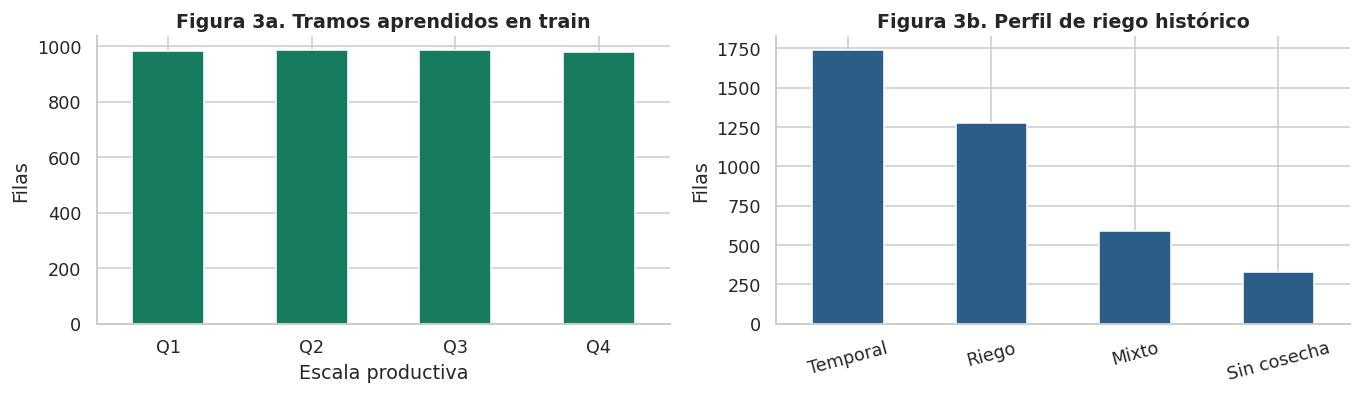

In [6]:
cats=prep._categories(train)
cat_rows=[]
for c in cats:
    for value,count in cats[c].value_counts(dropna=False).items():
        cat_rows.append({'variable':c,'nivel':str(value),'filas_train':int(count),
                         'agrupada_por_frecuencia':bool(count<prep.min_frequency)})
cat_counts=pd.DataFrame(cat_rows)
table(cat_counts,'08_frecuencias_categoricas')
bin_table=pd.DataFrame({'tramo':prep.bin_labels_,'limite_inferior':prep.bin_edges_[:-1],
                        'limite_superior':prep.bin_edges_[1:]})
table(bin_table,'09_limites_binning_train')
encoded_counts=pd.DataFrame({'variable':cats.columns,
                             'cardinalidad_original_train':[cats[c].nunique() for c in cats],
                             'columnas_onehot':[sum(n.startswith(c+'_') for n in prep.encoder_.get_feature_names_out()) for c in cats]})
table(encoded_counts,'10_cardinalidad_codificada')
fig,axes=plt.subplots(1,2,figsize=(12,3.6))
cats.escala_produccion.value_counts().reindex(prep.bin_labels_).plot.bar(ax=axes[0],rot=0,color='#177B60')
axes[0].set(title='Figura 3a. Tramos aprendidos en train',xlabel='Escala productiva',ylabel='Filas')
cats.perfil_riego_lag2.value_counts().plot.bar(ax=axes[1],rot=15,color='#2C5D86')
axes[1].set(title='Figura 3b. Perfil de riego histórico',xlabel='',ylabel='Filas')
savefig('fig03_categorias')

### 6. Transformaciones: diagnóstico antes de decidir

Se comparan identidad, `log1p` cuando el dominio es no negativo y Yeo–Johnson, que admite cero
y valores negativos. Box–Cox exigiría entradas estrictamente positivas; sumar una constante
arbitraria a toda la producción no resulta necesario aquí (The scikit-learn developers, s. f.-d).

Regla fijada antes de evaluar validación: proporciones, conteos y calendario conservan su escala
semántica. En el resto, si |asimetría| > 1, una transformación debe reducirla al menos 20%.
Se prefiere log1p por sencillez; Yeo–Johnson se utiliza si mejora la mejor alternativa al menos
0.2 unidades adicionales de asimetría absoluta. Los parámetros Yeo–Johnson se estiman en train.
Los umbrales son criterios diagnósticos explícitos, no un test de normalidad ni una optimización
del error futuro.

La comparación se realiza después de imputar X, tal como la verá el algoritmo; los indicadores
mantienen la información sobre ausencia. Asimetría próxima a cero no implica distribución normal:
los gráficos Q–Q permiten observar colas y acumulaciones. Los modelos de árboles no requieren
normalidad de las entradas; esta preparación facilita principalmente modelos sensibles a escalas,
distancias o regularización y la aplicación de PCA (The scikit-learn developers, s. f.-b, s. f.-d, s. f.-e).

,variable,asimetria_abs_original,asimetria_abs_log1p,asimetria_abs_yeojohnson,metodo,asimetria_abs_elegida,curtosis_exceso_original,lambda_yj_elegida
0,produccion_lag2,8.4183,0.5008,0.0011,yeo-johnson,0.0011,75.4921,-0.0649
1,produccion_lag3,8.4924,0.5709,0.0154,yeo-johnson,0.0154,77.0710,-0.0704
2,produccion_lag4,8.5786,0.6435,0.0274,yeo-johnson,0.0274,79.1023,-0.0771
3,cosechada_lag2,8.3788,0.9871,0.0635,yeo-johnson,0.0635,75.2414,-0.1802
4,sembrada_lag2,8.1630,0.9906,0.0981,yeo-johnson,0.0981,70.9962,-0.2077
5,valor_lag2,8.9629,1.5387,0.1417,yeo-johnson,0.1417,87.0342,0.0858
6,rendimiento_lag2,2.3845,0.1772,0.0099,log1p,0.1772,9.1403,NaN
7,precio_lag2,0.5919,0.7236,0.0438,identidad,0.5919,0.0245,NaN
8,valor_por_ha_lag2,2.1372,0.2789,0.0071,yeo-johnson,0.0071,8.1737,0.1247
9,media_produccion_3,8.3552,0.6919,0.0176,yeo-johnson,0.0176,73.9087,-0.0893


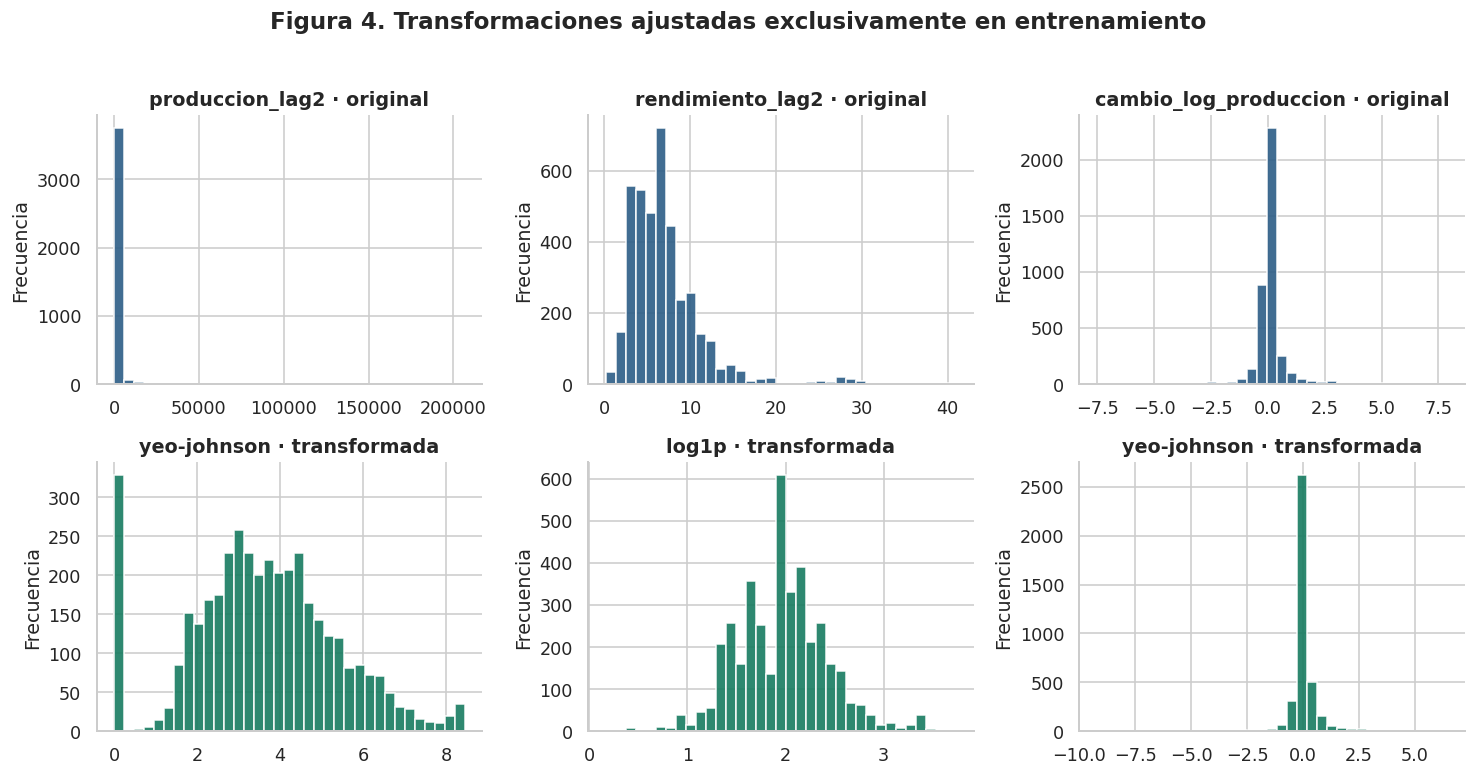

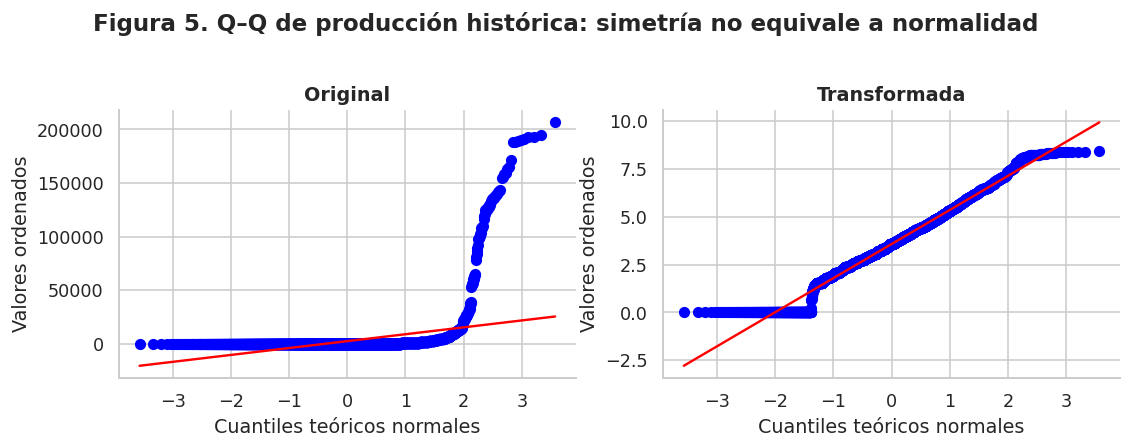

In [7]:
table(prep.transform_report_,'11_comparacion_transformaciones')
before=train[NUMERIC].fillna(prep.medians_)
after=prep._shape_transform(train)
chosen=['produccion_lag2','rendimiento_lag2','cambio_log_produccion']
fig,axes=plt.subplots(2,3,figsize=(13,6.6))
for j,c in enumerate(chosen):
    axes[0,j].hist(before[c],bins=35,color='#2C5D86',alpha=.9)
    axes[0,j].set(title=c+' · original',ylabel='Frecuencia')
    axes[1,j].hist(after[c],bins=35,color='#177B60',alpha=.9)
    axes[1,j].set(title=prep.methods_[c]+' · transformada',ylabel='Frecuencia')
fig.suptitle('Figura 4. Transformaciones ajustadas exclusivamente en entrenamiento',y=1.02,fontweight='bold')
savefig('fig04_distribuciones_transformadas')
fig,axes=plt.subplots(1,2,figsize=(10,3.8))
for ax,values,label in [(axes[0],before.produccion_lag2,'Original'),(axes[1],after.produccion_lag2,'Transformada')]:
    stats.probplot(values,dist='norm',plot=ax)
    ax.set(title=label,xlabel='Cuantiles teóricos normales',ylabel='Valores ordenados')
fig.suptitle('Figura 5. Q–Q de producción histórica: simetría no equivale a normalidad',y=1.02,fontweight='bold')
savefig('fig05_qq_produccion')

### 7. Escalamiento y estabilidad del esquema

Después de transformar, se aplica `StandardScaler`: `z = (x − media_train) / desviacion_train`.
La escala corresponde a la desviación poblacional (`ddof=0`). Ajustar media, escala o mediana
con validación o reserva introduciría información del periodo evaluado (The scikit-learn developers, s. f.-a, s. f.-e).

Se comprueba media cero y desviación uno en las columnas continuas no constantes de entrenamiento.
Las variables binarias permanecen 0/1. Estandarizar evita que las unidades (pesos, hectáreas,
toneladas) dominen una penalización por su magnitud; **no garantiza igual importancia predictiva**.
La validación puede tener medias distintas de cero: no se reescala para ocultar cambios temporales.
No se usa MinMax porque no impide que un valor posterior supere el máximo de entrenamiento.

,variable,media_entrenamiento,escala_entrenamiento,mediana_imputacion,media_z_train,sd_z_train_ddof0,media_z_validacion
0,produccion_lag2,3.5791,1.7970,58.5000,0.0000,1.0000,0.1756
1,produccion_lag3,3.5691,1.6644,60.0000,-0.0000,1.0000,0.1436
2,produccion_lag4,3.5340,1.5516,60.0000,0.0000,1.0000,0.0946
3,cosechada_lag2,1.9662,1.0881,10.0000,0.0000,1.0000,0.1537
4,sembrada_lag2,2.1375,0.8771,17.0000,0.0000,1.0000,0.1683
5,valor_lag2,23.8340,10.8077,"350,250.0000",-0.0000,1.0000,0.3235
6,rendimiento_lag2,1.9690,0.4685,6.2000,0.0000,1.0000,0.2142
7,precio_lag2,"7,791.5481","3,855.4673","7,500.0000",0.0000,1.0000,1.3888
8,valor_por_ha_lag2,22.2278,2.9765,"42,000.0000",0.0000,1.0000,0.9175
9,media_produccion_3,3.4973,1.4461,63.6000,0.0000,1.0000,0.1382


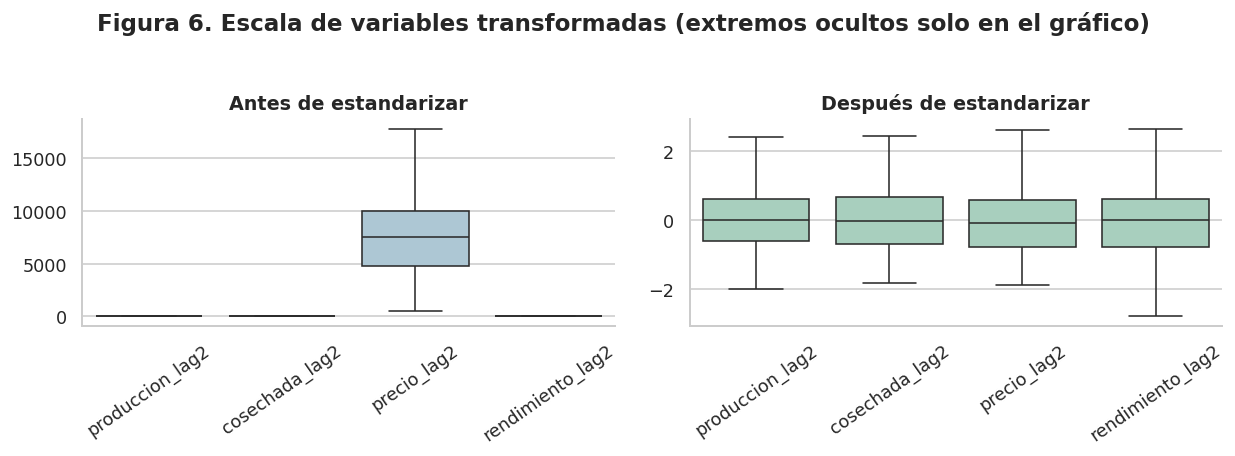

In [8]:
full_train=prep.full(train)
full_valid=prep.full(valid)
scales=prep.scaling_report_.copy()
scales['media_z_train']=full_train[NUMERIC].mean().to_numpy()
scales['sd_z_train_ddof0']=full_train[NUMERIC].std(ddof=0).to_numpy()
scales['media_z_validacion']=full_valid[NUMERIC].mean().to_numpy()
table(scales,'12_parametros_y_verificacion_escalamiento')
nonconstant=full_train[NUMERIC].var(ddof=0)>1e-14
assert np.allclose(full_train[NUMERIC].mean(),0,atol=1e-10)
assert np.allclose(full_train[NUMERIC].std(ddof=0)[nonconstant],1,atol=1e-10)
fig,axes=plt.subplots(1,2,figsize=(11,3.8))
show=['produccion_lag2','cosechada_lag2','precio_lag2','rendimiento_lag2']
sns.boxplot(data=after[show],ax=axes[0],showfliers=False,color='#A6C9DB')
sns.boxplot(data=full_train[show],ax=axes[1],showfliers=False,color='#A1D6BF')
for ax in axes:
    ax.tick_params(axis='x',rotation=35)
axes[0].set_title('Antes de estandarizar');axes[1].set_title('Después de estandarizar')
fig.suptitle('Figura 6. Escala de variables transformadas (extremos ocultos solo en el gráfico)',y=1.04,fontweight='bold')
savefig('fig06_escalamiento')

### 8. Selección por filtros: decisiones respaldadas por diagnósticos

1. **Varianza nula (`threshold=0`).** Elimina columnas que no distinguen ninguna fila de train.
   El criterio es invariante a las unidades. No se descartan automáticamente indicadores poco
   frecuentes: una varianza pequeña puede representar un evento relevante (The scikit-learn developers, s. f.-b).
2. **Redundancia monotónica.** En atributos numéricos no constantes, se elimina uno de cada par
   con |Spearman| > 0.95. Se usa Spearman por asimetría y relaciones monótonas; se calcula con X
   transformada e imputada de train, nunca con el objetivo o la reserva. El orden fijo favorece
   producción reciente, historia explícita y magnitudes directas antes de resúmenes derivados.
   Se reportan las parejas y la sensibilidad a 0.90 / 0.95 / 0.99; 0.95 se mantiene como compromiso
   conservador de redundancia muy alta. No se afirma que una correlación bivariada baja implique
   irrelevancia para modelos no lineales.
3. **Indicadores idénticos.** Se conserva uno cuando dos columnas binarias son exactamente iguales
   en train; se prioriza `sin_cosecha_lag2` sobre un indicador técnico equivalente. Se documentan
   ambas columnas para permitir auditar esa equivalencia en otras cohortes.

No se aplica chi-cuadrado ni ANOVA de clases: la variable objetivo planteada es continua, no una
etiqueta de clasificación. La rúbrica pide métodos fundamentados, no ejecutar todos los ejemplos.
Los filtros elegidos no usan y; una selección supervisada adicional deberá evaluarse dentro de
validación temporal en la fase de modelado.

Dimensión completa: 74 | interpretable: 51 | atributos numéricos retenidos: 18


,variable,razon
0,fraccion_siniestrada_lag2,Varianza cero en entrenamiento
1,falta_produccion_lag2,Varianza cero en entrenamiento
2,falta_cosechada_lag2,Varianza cero en entrenamiento
3,falta_sembrada_lag2,Varianza cero en entrenamiento
4,falta_valor_lag2,Varianza cero en entrenamiento
5,falta_fraccion_cosechada_lag2,Varianza cero en entrenamiento
6,falta_fraccion_siniestrada_lag2,Varianza cero en entrenamiento
7,falta_participacion_estatal_lag2,Varianza cero en entrenamiento
8,falta_n_observaciones_3,Varianza cero en entrenamiento
9,falta_indice_anio,Varianza cero en entrenamiento


,variable_eliminada,variable_conservada,rho_spearman,criterio
0,cosechada_lag2,produccion_lag2,0.9609,|rho| > 0.95; prioridad de dominio
1,valor_lag2,produccion_lag2,0.9664,|rho| > 0.95; prioridad de dominio
2,media_produccion_3,produccion_lag3,0.9619,|rho| > 0.95; prioridad de dominio


,variable_eliminada,variable_conservada,criterio
0,falta_rendimiento_lag2,sin_cosecha_lag2,Indicadores idénticos en entrenamiento
1,falta_precio_lag2,sin_cosecha_lag2,Indicadores idénticos en entrenamiento
2,falta_valor_por_ha_lag2,sin_cosecha_lag2,Indicadores idénticos en entrenamiento
3,falta_sd_produccion_3,falta_media_produccion_3,Indicadores idénticos en entrenamiento
4,falta_min_produccion_3,falta_media_produccion_3,Indicadores idénticos en entrenamiento
5,falta_max_produccion_3,falta_media_produccion_3,Indicadores idénticos en entrenamiento
6,falta_cambio_log_produccion,falta_produccion_lag3,Indicadores idénticos en entrenamiento
7,falta_cambio_log_cosechada,falta_produccion_lag3,Indicadores idénticos en entrenamiento
8,falta_fraccion_riego_lag2,sin_cosecha_lag2,Indicadores idénticos en entrenamiento
9,perfil_riego_lag2_Sin cosecha,sin_cosecha_lag2,Indicadores idénticos en entrenamiento


,umbral_abs_spearman,numericas_conservadas,numericas_eliminadas,seleccion
0,0.9000,16,5,"produccion_lag2, produccion_lag3, produccion_lag4, sembrada_lag2, rendimiento_lag2, precio_lag2, valor_por_ha_lag2, sd_produccion_3, cv_produccion_3, cambio_log_produccion, cambio_log_cosechada, fraccion_cosechada_lag2, fraccion_riego_lag2, participacion_estatal_lag2, n_observaciones_3, indice_anio"
1,0.9500,18,3,"produccion_lag2, produccion_lag3, produccion_lag4, sembrada_lag2, rendimiento_lag2, precio_lag2, valor_por_ha_lag2, sd_produccion_3, cv_produccion_3, min_produccion_3, max_produccion_3, cambio_log_produccion, cambio_log_cosechada, fraccion_cosechada_lag2, fraccion_riego_lag2, participacion_estatal_lag2, n_observaciones_3, indice_anio"
2,0.9900,20,1,"produccion_lag2, produccion_lag3, produccion_lag4, cosechada_lag2, sembrada_lag2, valor_lag2, rendimiento_lag2, precio_lag2, valor_por_ha_lag2, media_produccion_3, sd_produccion_3, cv_produccion_3, min_produccion_3, cambio_log_produccion, cambio_log_cosechada, fraccion_cosechada_lag2, fraccion_riego_lag2, participacion_estatal_lag2, n_observaciones_3, indice_anio"


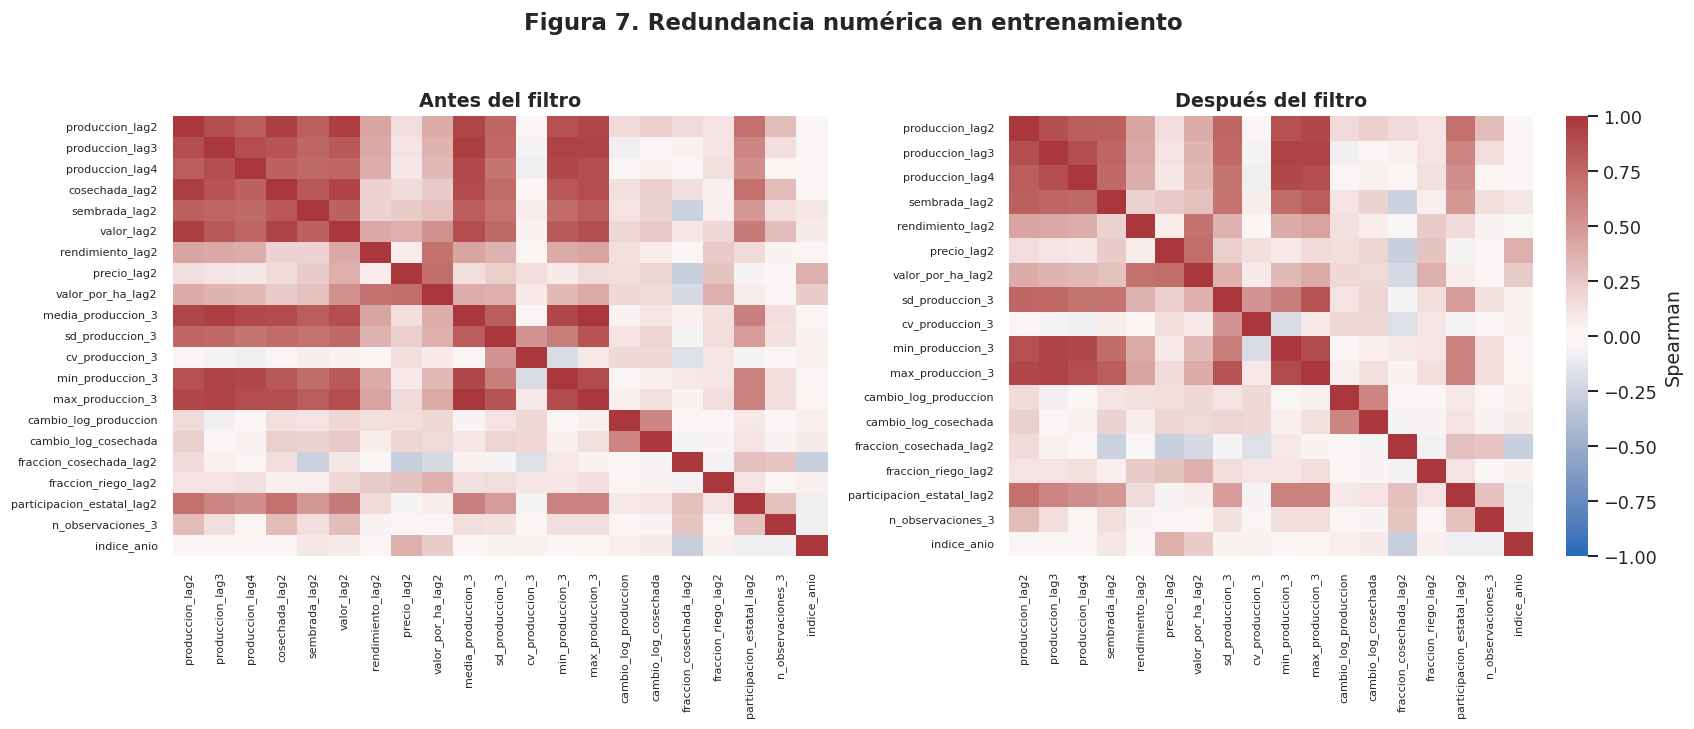

In [9]:
table(pd.DataFrame({'variable':prep.constant_names_,'razon':'Varianza cero en entrenamiento'}),'13_columnas_constantes')
table(prep.correlation_report_,'14_pares_redundantes')
table(prep.duplicate_report_,'15_indicadores_identicos')
sens=[]
for threshold in [.90,.95,.99]:
    kept=[]
    for c in prep.corr_.columns:
        if not any(abs(prep.corr_.loc[c,k])>threshold for k in kept):
            kept.append(c)
    sens.append({'umbral_abs_spearman':threshold,'numericas_conservadas':len(kept),
                 'numericas_eliminadas':len(prep.corr_)-len(kept),
                 'seleccion':', '.join(kept)})
table(pd.DataFrame(sens),'16_sensibilidad_correlacion')
fig,axes=plt.subplots(1,2,figsize=(15,6.2))
sns.heatmap(prep.corr_,vmin=-1,vmax=1,cmap='vlag',center=0,ax=axes[0],cbar=False)
sns.heatmap(prep.corr_.loc[prep.selected_numeric_,prep.selected_numeric_],
            vmin=-1,vmax=1,cmap='vlag',center=0,ax=axes[1],cbar_kws={'label':'Spearman'})
for ax in axes:
    ax.tick_params(axis='both',labelsize=7)
axes[0].set_title('Antes del filtro');axes[1].set_title('Después del filtro')
fig.suptitle('Figura 7. Redundancia numérica en entrenamiento',y=1.02,fontweight='bold')
savefig('fig07_correlacion')
print('Dimensión completa:',prep.full(train).shape[1],
      '| interpretable:',prep.selected(train).shape[1],
      '| atributos numéricos retenidos:',len(prep.selected_numeric_))

### 9. Extracción mediante PCA: compresión medible y costo de interpretación

PCA se ajusta únicamente sobre las variables **numéricas seleccionadas y estandarizadas de train**.
Las categorías y los indicadores binarios se conservan fuera de PCA: así no se mezclan coordenadas
de estado con medidas agronómicas. Se usa SVD completa y se solicita retener al menos 95% de la
varianza de ese bloque numérico. PCA centra, pero no estandariza por sí mismo; el paso anterior
es necesario (The scikit-learn developers, s. f.-c).

Se presentan la curva acumulada, las dimensiones necesarias para 90%, 95% y 99%, y las cargas
de los primeros componentes. La varianza explicada describe X, no la información predictiva
sobre y. Los componentes combinan variables y pierden interpretación directa; sus signos son
convencionales. Se conserva también la representación interpretable para el Avance 3.

,componente,varianza_explicada,varianza_acumulada
0,1,0.3577,0.3577
1,2,0.1347,0.4924
2,3,0.1093,0.6017
3,4,0.0793,0.6811
4,5,0.0688,0.7498
5,6,0.0608,0.8107
6,7,0.0498,0.8605
7,8,0.0428,0.9033
8,9,0.0360,0.9393
9,10,0.0313,0.9706


,varianza_objetivo,componentes
0,0.9000,8
1,0.9500,10
2,0.9900,13


,variable,PC01,PC02,PC03,PC04,PC05,PC06,PC07,PC08,PC09,PC10
0,produccion_lag2,0.3667,-0.0087,0.1918,-0.0243,-0.0086,0.1307,-0.0741,0.0171,0.0014,0.0389
1,produccion_lag3,0.3649,-0.1827,-0.0793,0.0317,-0.0340,0.0151,-0.0097,-0.0804,0.0560,-0.0408
2,produccion_lag4,0.3445,-0.1404,-0.0609,0.0480,-0.1723,-0.0736,0.0524,-0.1088,-0.0075,0.0313
3,sembrada_lag2,0.3155,0.0417,-0.0435,0.3126,-0.1115,0.1141,0.0474,0.1132,-0.3157,0.2787
4,rendimiento_lag2,0.1894,0.1274,-0.1089,-0.3942,0.0341,-0.4695,-0.3267,0.3525,0.2078,0.1642
5,precio_lag2,0.1060,0.3999,-0.2838,-0.1081,-0.0156,0.3685,0.0243,-0.1719,-0.3115,-0.4677
6,valor_por_ha_lag2,0.2010,0.3642,-0.2769,-0.3469,-0.0024,-0.0571,-0.2135,0.1091,-0.0846,-0.2077
7,sd_produccion_3,0.3264,0.1092,-0.0084,0.3148,0.2592,-0.0937,-0.0729,-0.0630,0.1442,-0.0603
8,cv_produccion_3,0.0033,0.2997,0.0076,0.4280,0.6013,-0.1157,-0.1085,-0.0424,0.2007,-0.0824
9,min_produccion_3,0.3573,-0.1668,0.0096,-0.0451,-0.2103,0.0054,0.0211,-0.0894,0.0007,0.0164


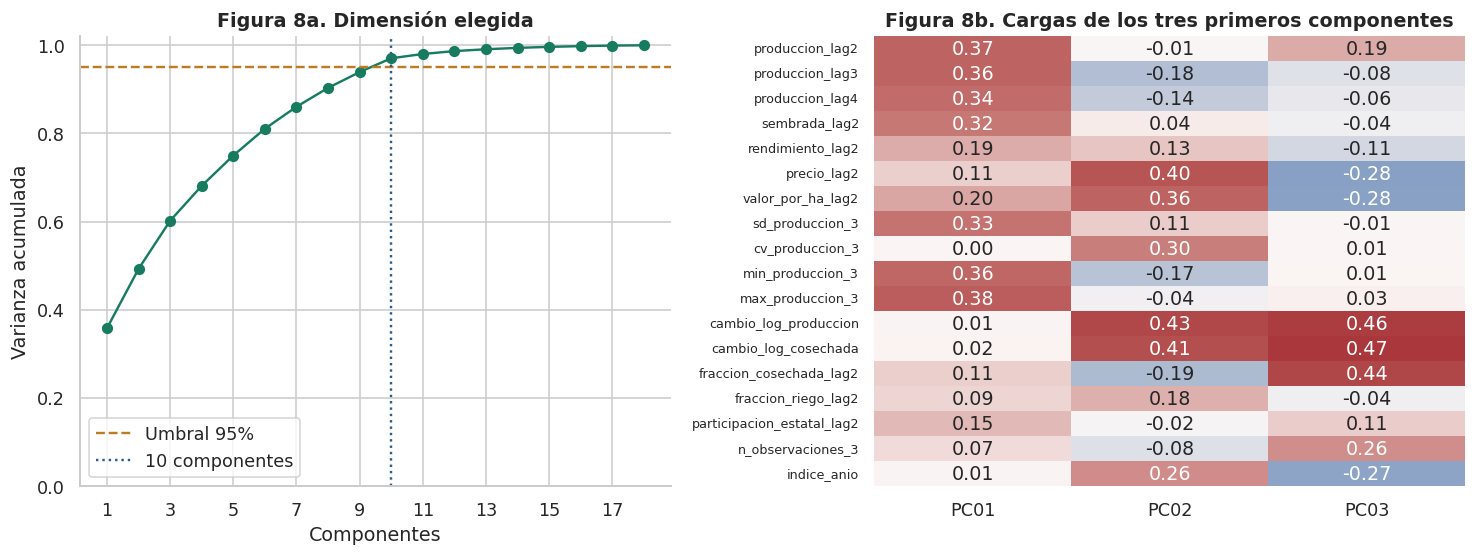

,representacion,filas,columnas,bytes_matriz_densa_float64,reduccion_columnas_pct
0,Completa,3930,74,2326560,0.0000
1,Seleccionada,3930,51,1603440,31.0811
2,PCA + indicadores,3930,43,1351920,41.8919


**Interpretación de las cargas.** En PC01 predominan max_produccion_3, produccion_lag2, produccion_lag3; resume principalmente escala productiva. PC02 da mayor peso absoluto a cambio_log_produccion, cambio_log_cosechada, precio_lag2. Son combinaciones estadísticas de atributos, no factores físicos identificados ni efectos causales.

In [10]:
table(prep.pca_report_,'17_varianza_pca')
pca_thresholds=pd.DataFrame({'varianza_objetivo':[.90,.95,.99],
    'componentes':[int(np.searchsorted(prep.pca_report_.varianza_acumulada,x)+1) for x in [.90,.95,.99]]})
table(pca_thresholds,'18_sensibilidad_pca')
loadings=pd.DataFrame(prep.pca_.components_.T,index=prep.selected_numeric_,
                       columns=[f'PC{i+1:02d}' for i in range(prep.pca_.n_components_)])
table(loadings.reset_index(names='variable'),'19_cargas_pca')
fig,axes=plt.subplots(1,2,figsize=(13,5))
axes[0].plot(prep.pca_report_.componente,prep.pca_report_.varianza_acumulada,marker='o',color='#177B60')
axes[0].axhline(.95,color='#BD7C22',ls='--',label='Umbral 95%')
axes[0].axvline(prep.pca_.n_components_,color='#2C5D86',ls=':',label=f'{prep.pca_.n_components_} componentes')
axes[0].set(xlabel='Componentes',ylabel='Varianza acumulada',ylim=(0,1.02),title='Figura 8a. Dimensión elegida');axes[0].legend()
axes[0].set_xticks(np.arange(1,len(prep.pca_report_)+1,2))
sns.heatmap(loadings.iloc[:,:3],annot=True,fmt='.2f',cmap='vlag',center=0,ax=axes[1],cbar=False)
axes[1].tick_params(axis='y',labelsize=8);axes[1].set_title('Figura 8b. Cargas de los tres primeros componentes')
savefig('fig08_pca')
sizes=[]
for name,method in [('Completa',prep.full),('Seleccionada',prep.selected),('PCA + indicadores',prep.pca)]:
    arr=method(train).to_numpy(dtype=np.float64)
    sizes.append({'representacion':name,'filas':arr.shape[0],'columnas':arr.shape[1],
                  'bytes_matriz_densa_float64':arr.nbytes})
sizes=pd.DataFrame(sizes)
sizes['reduccion_columnas_pct']=100*(1-sizes.columnas/sizes.columnas.iloc[0])
table(sizes,'20_dimensiones_y_memoria')
top_loadings={c:loadings[c].abs().nlargest(3).index.tolist() for c in loadings.columns[:3]}
display(Markdown('**Interpretación de las cargas.** En PC01 predominan '+', '.join(top_loadings['PC01'])+
                 '; resume principalmente escala productiva. PC02 da mayor peso absoluto a '+
                 ', '.join(top_loadings['PC02'])+'. Son combinaciones estadísticas de atributos, '
                 'no factores físicos identificados ni efectos causales.'))

### 10. Prueba instrumental en validación: qué cambia y qué no se puede afirmar

Se realiza una comprobación pequeña para relacionar la preparación con su propósito. No sustituye
el baseline ni la comparación de modelos del Avance 3. Todas las variantes Ridge usan
`alpha=1`, intercepto y objetivo `log1p(produccion_t)`, se ajustan en train y se puntúan exactamente
en las mismas filas de 2018–2020. No se buscan hiperparámetros. Se compara una referencia mínima
con log-producción t−2 y calendario contra los tres conjuntos de atributos.

La persistencia t−2 es una referencia sin ajuste. MAE y RMSE se expresan en toneladas; RMSLE
permite observar errores relativos suavizados. Las predicciones Ridge se regresan con `expm1`
y los valores negativos se llevan a cero, contabilizando cuántos se limitaron. No se aplica
corrección de sesgo de retransformación: un modelo en log no optimiza directamente toneladas.
Por ello los indicadores pueden favorecer variantes diferentes.

Los tiempos son mediciones orientativas de una sola máquina y tres ajustes pequeños; no son
una garantía de aceleración. La reducción de columnas y bytes sí es una medición directa.
No se evalúa rendimiento predictivo de 2023 ni 2025 en esta fase.

,variante,columnas,MAE_t,RMSE_t,RMSLE,ajuste_ms_mediana,predicciones_limitadas_a_cero
0,Persistencia t-2,1,584.3078,"2,347.0878",0.9620,0.0000,0
1,Ridge mínimo,2,"1,422.0900","8,063.9493",0.8978,0.5315,0
2,Ridge completo,74,"1,553.4258","10,957.5560",0.6602,2.3237,0
3,Ridge seleccionado,51,"1,483.1954","9,466.6816",0.6709,2.0585,1
4,Ridge PCA,43,"1,933.3541","12,471.9290",0.6874,1.5489,0


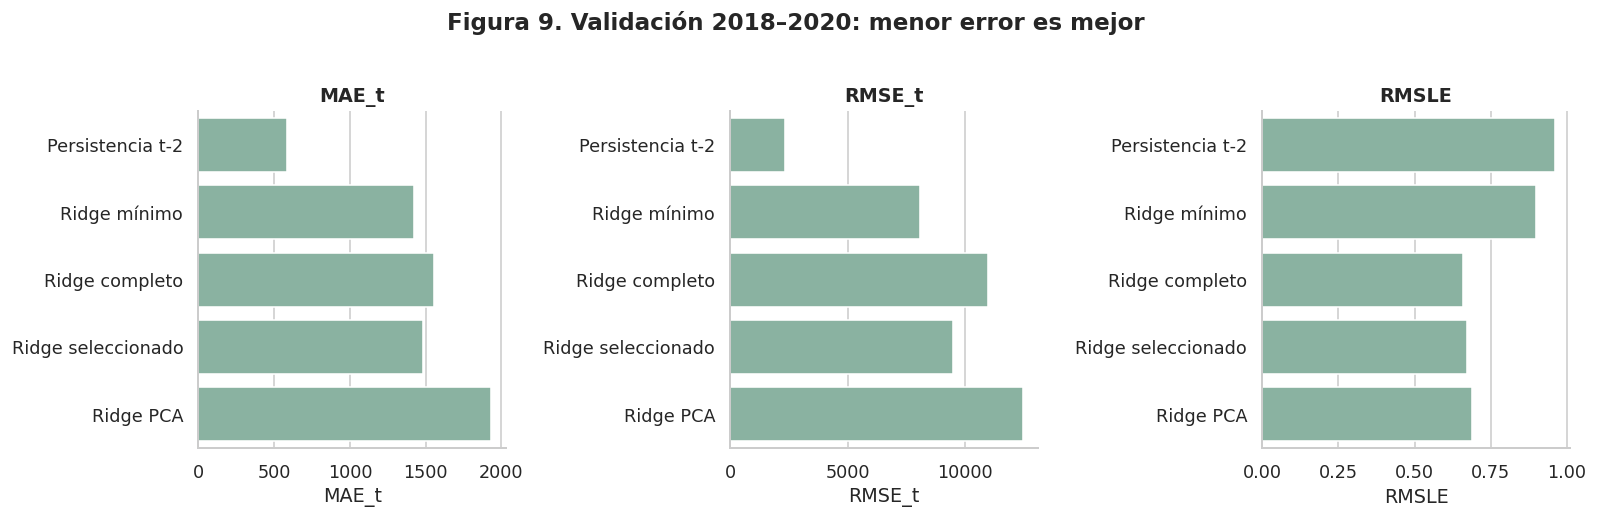

**Lectura de la prueba.** El menor MAE corresponde a **Persistencia t-2**; el menor RMSLE corresponde a **Ridge completo**. La asimetría reducida y la compresión de PCA no acreditan por sí solas mayor precisión. Se entrega la matriz seleccionada como representación interpretable y PCA como alternativa, sin declarar un modelo ganador para producción.

In [11]:
def metrics(y,p):
    return {'MAE_t':mean_absolute_error(y,p),'RMSE_t':root_mean_squared_error(y,p),
            'RMSLE':np.sqrt(mean_squared_log_error(y,p))}

probes=[]
probes.append({'variante':'Persistencia t-2','columnas':1,**metrics(valid.produccion_t,valid.produccion_lag2),
               'ajuste_ms_mediana':0.0,'predicciones_limitadas_a_cero':0})
base_train=pd.DataFrame({'log_produccion_lag2':np.log1p(train.produccion_lag2),'indice_anio':train.indice_anio})
base_valid=pd.DataFrame({'log_produccion_lag2':np.log1p(valid.produccion_lag2),'indice_anio':valid.indice_anio})
base_scaler=StandardScaler().fit(base_train)
variants={'Ridge mínimo':(base_scaler.transform(base_train),base_scaler.transform(base_valid)),
          'Ridge completo':(prep.full(train),prep.full(valid)),
          'Ridge seleccionado':(prep.selected(train),prep.selected(valid)),
          'Ridge PCA':(prep.pca(train),prep.pca(valid))}
predictions=pd.DataFrame({'cvegeo':valid.cvegeo,'anio':valid.anio,'observado_t':valid.produccion_t,
                          'Persistencia t-2':valid.produccion_lag2})
for name,(xt,xv) in variants.items():
    timings=[]
    for _ in range(3):
        start=time.perf_counter()
        model=Ridge(alpha=1.0).fit(xt,np.log1p(train.produccion_t))
        timings.append(1000*(time.perf_counter()-start))
    original_pred=np.expm1(model.predict(xv))
    pred=np.maximum(original_pred,0)
    probes.append({'variante':name,'columnas':xt.shape[1],**metrics(valid.produccion_t,pred),
                   'ajuste_ms_mediana':float(np.median(timings)),
                   'predicciones_limitadas_a_cero':int((original_pred<0).sum())})
    predictions[name]=pred
probe=pd.DataFrame(probes)
table(probe,'21_comparacion_instrumental_validacion')
predictions.to_csv(OUT/'22_predicciones_solo_validacion.csv',index=False)
fig,axes=plt.subplots(1,3,figsize=(14,4.4))
for ax,col in zip(axes,['MAE_t','RMSE_t','RMSLE']):
    sns.barplot(data=probe,x=col,y='variante',ax=ax,color='#83B9A2')
    ax.set(ylabel='',title=col)
fig.suptitle('Figura 9. Validación 2018–2020: menor error es mejor',y=1.02,fontweight='bold')
savefig('fig09_validacion')
best_mae=probe.loc[probe.MAE_t.idxmin(),'variante']
best_rmsle=probe.loc[probe.RMSLE.idxmin(),'variante']
display(Markdown(f'**Lectura de la prueba.** El menor MAE corresponde a **{best_mae}**; '
                 f'el menor RMSLE corresponde a **{best_rmsle}**. '
                 'La asimetría reducida y la compresión de PCA no acreditan por sí solas mayor precisión. '
                 'Se entrega la matriz seleccionada como representación interpretable y PCA como alternativa, '
                 'sin declarar un modelo ganador para producción.'))

### 11. Aseguramiento de calidad y exportación reproducible

Se prueban los riesgos concretos de esta preparación: confundir filas con años, mezclar municipios,
usar el objetivo en X, ajustar estadísticas con validación o alterar las columnas ante una categoría
nueva. Las perturbaciones artificiales siguientes existen **solo en copias para probar el código**;
no se incorporan a los datos ni a los resultados del proyecto.

La prueba de disponibilidad temporal verifica fechas de medición, no versiones históricas de
publicación. También se controla la equivalencia de los indicadores filtrados en las cohortes
posteriores: si deja de cumplirse, deberá revisarse el esquema antes de reentrenar.

In [12]:
checks=[]
def check(name,condition,detail):
    assert bool(condition),name
    checks.append({'control':name,'resultado':'OK','evidencia':detail})

check('Fuente fijada por SHA-256',hashlib.sha256((ROOT/'data/raw/siap_produccion.csv').read_bytes()).hexdigest()==RAW_SHA256,RAW_SHA256)
check('Clave municipal anual única',not panel.duplicated(['cvegeo','anio']).any(),f'{len(panel)} filas sin claves repetidas')
check('Separación de la historia estatal',len(historia_estatal)==981 and historia_estatal.CVE_MUN.eq(999).all(),'1980–2002 no se asignan a municipios')
check('Cuarentena preservada',len(cuarentena)==900 and not panel.anio.eq(2024).any(),'2024 no participa en el panel')
check('Estadísticas ajustadas solo en train',prep.fit_years_==list(range(2007,2016)),str(prep.fit_years_))
check('Objetivo observado, sin imputación',all(d.produccion_t.notna().all() for d in splits.values()),'Ninguna etiqueta fue rellenada')
check('Última medición anterior al objetivo',(cohort.anio_ultima_medicion<=cohort.anio-2).all(),'Todas las mediciones de entrada son de t-2 o anteriores')

# Comparación con unión explícita por clave y año; incluye el hueco de 2024.
lag_reference=panel[['cvegeo','anio','produccion_t']].copy()
lag_reference['anio']+=2
lag_reference=lag_reference.rename(columns={'produccion_t':'referencia_lag2'})
lag_check=features.merge(lag_reference,on=['cvegeo','anio'],how='left',validate='one_to_one')
check('Rezago por calendario y municipio',np.allclose(lag_check.produccion_lag2,lag_check.referencia_lag2,equal_nan=True),
      'Unión independiente por cvegeo y año+2; 2025 usa 2023')

# Cambiar mediciones de 2021 en adelante no debe modificar X para t<=2022.
raw_future=raw.copy()
raw_future.loc[raw_future['AÑO']>=2021,list(ADDITIVE)] *= 13
panel_future,_,_=prepare_panel(raw_future)
future_features=build_features(panel_future)
feature_cols=NUMERIC+CATEGORICAL+['sin_cosecha_lag2']
a=features.loc[features.anio<=2022,feature_cols].reset_index(drop=True)
b=future_features.loc[future_features.anio<=2022,feature_cols].reset_index(drop=True)
pd.testing.assert_frame_equal(a,b)
check('Perturbación futura no cambia el pasado',True,'Copias con magnitudes futuras multiplicadas por 13; X anterior idéntica')

changed_y=valid.copy();changed_y['produccion_t']=changed_y.produccion_t*31+99
check('El objetivo no entra en transform',np.array_equal(prep.selected(valid).to_numpy(),prep.selected(changed_y).to_numpy()),
      'X idéntica al modificar solamente y')
saved_mean=prep.scaler_.mean_.copy();saved_components=prep.pca_.components_.copy()
expected_selected=prep.selected(train).columns.tolist();expected_pca=prep.pca(train).columns.tolist()
for name,d in splits.items():
    xs,xp=prep.selected(d),prep.pca(d)
    check('Matriz válida '+name,np.isfinite(xs.to_numpy()).all() and np.isfinite(xp.to_numpy()).all()
          and xs.columns.tolist()==expected_selected and xp.columns.tolist()==expected_pca,
          f'{len(d)} filas; {xs.shape[1]} columnas seleccionadas y {xp.shape[1]} con PCA')
check('Transform no reajusta parámetros',np.array_equal(saved_mean,prep.scaler_.mean_) and np.array_equal(saved_components,prep.pca_.components_),
      'Media y componentes idénticos después de transformar todas las cohortes')
unseen=valid.head(2).copy();unseen['estado_lag2']='99'
check('Estado no visto compatible',np.isfinite(prep.selected(unseen).to_numpy()).all()
      and prep.selected(unseen).columns.tolist()==expected_selected,'Categoría desconocida con esquema constante')

equivalence=[]
for name,d in splits.items():
    all_x=prep.full(d)
    for row in prep.duplicate_report_.itertuples():
        mismatches=int((all_x[row.variable_eliminada]!=all_x[row.variable_conservada]).sum())
        equivalence.append({'particion':name,'eliminada':row.variable_eliminada,
                            'conservada':row.variable_conservada,'filas_no_equivalentes':mismatches})
equivalence=pd.DataFrame(equivalence)
table(equivalence,'23_auditoria_indicadores')
check('Indicadores filtrados siguen siendo equivalentes',equivalence.filas_no_equivalentes.sum()==0,
      'Sin divergencias en las cohortes transformadas')

joblib.dump(prep,DATA/'preprocesador_avance2.joblib',compress=3)
restored=joblib.load(DATA/'preprocesador_avance2.joblib')
check('Serialización reproducible',np.array_equal(prep.selected(valid).to_numpy(),restored.selected(valid).to_numpy()),
      'Restaurar el objeto produce exactamente la misma matriz')
table(pd.DataFrame(checks),'24_controles_calidad')

,particion,eliminada,conservada,filas_no_equivalentes
0,train,falta_rendimiento_lag2,sin_cosecha_lag2,0
1,train,falta_precio_lag2,sin_cosecha_lag2,0
2,train,falta_valor_por_ha_lag2,sin_cosecha_lag2,0
3,train,falta_sd_produccion_3,falta_media_produccion_3,0
4,train,falta_min_produccion_3,falta_media_produccion_3,0
5,train,falta_max_produccion_3,falta_media_produccion_3,0
6,train,falta_cambio_log_produccion,falta_produccion_lag3,0
7,train,falta_cambio_log_cosechada,falta_produccion_lag3,0
8,train,falta_fraccion_riego_lag2,sin_cosecha_lag2,0
9,train,perfil_riego_lag2_Sin cosecha,sin_cosecha_lag2,0


,control,resultado,evidencia
0,Fuente fijada por SHA-256,OK,f195190c043409188741ea4a6a2bbb44343aaeaa1f2e02dc17b6bd5f394f9dd3
1,Clave municipal anual única,OK,11665 filas sin claves repetidas
2,Separación de la historia estatal,OK,1980–2002 no se asignan a municipios
3,Cuarentena preservada,OK,2024 no participa en el panel
4,Estadísticas ajustadas solo en train,OK,"[2007, 2008, 2009, 2010, 2011, 2012, 2013, 2014, 2015]"
5,"Objetivo observado, sin imputación",OK,Ninguna etiqueta fue rellenada
6,Última medición anterior al objetivo,OK,Todas las mediciones de entrada son de t-2 o anteriores
7,Rezago por calendario y municipio,OK,Unión independiente por cvegeo y año+2; 2025 usa 2023
8,Perturbación futura no cambia el pasado,OK,Copias con magnitudes futuras multiplicadas por 13; X anterior idéntica
9,El objetivo no entra en transform,OK,X idéntica al modificar solamente y


In [13]:
# Exportar X e y por separado evita incluir el objetivo accidentalmente en un estimador.
matrix_manifest=[]
for name,d in splits.items():
    xs,xp=prep.selected(d),prep.pca(d)
    np.savez_compressed(DATA/f'matrices_{name}.npz',
                        X_seleccionada=xs.to_numpy(dtype=np.float64),
                        columnas_seleccionada=np.asarray(xs.columns,dtype=str),
                        X_pca=xp.to_numpy(dtype=np.float64),columnas_pca=np.asarray(xp.columns,dtype=str))
    d[['cvegeo','anio','anio_ultima_medicion','produccion_t','particion']].reset_index(drop=True).to_csv(DATA/f'claves_objetivo_{name}.csv',index=False)
    matrix_manifest.append({'particion':name,'filas':len(d),'columnas_seleccionadas':xs.shape[1],
                            'columnas_pca':xp.shape[1],'archivo':f'data/avance2/matrices_{name}.npz'})

cohort[['cvegeo','anio','particion','produccion_t']+NUMERIC+CATEGORICAL+['sin_cosecha_lag2']].to_csv(DATA/'atributos_antes_imputacion.csv',index=False)
features.loc[features.observado_objetivo & features.particion.ne('fuera_de_particion') & ~features.con_historia_minima,
             ['cvegeo','anio','particion','produccion_t']].to_csv(DATA/'municipios_sin_historia.csv',index=False)
matrix_schema=[]
corr_removed=set(prep.correlation_report_.variable_eliminada)
duplicate_removed=set(prep.duplicate_report_.variable_eliminada)
for c in prep.full(train):
    reason=('Varianza cero' if c in prep.constant_names_ else 'Redundancia Spearman' if c in corr_removed
            else 'Indicador idéntico' if c in duplicate_removed else 'Conservada')
    matrix_schema.append({'columna':c,'decision':reason,'en_matriz_seleccionada':c in prep.selected_names_,
                           'entra_a_PCA':c in prep.selected_numeric_})
pd.DataFrame(matrix_schema).to_csv(DATA/'esquema_columnas.csv',index=False)
metadata={'proyecto':'Avocado Insights','equipo':4,'fase':'Avance 2','fecha':'2026-10-11',
          'repositorio_base_commit':'79de83046351f162cd0024cdac3424bfc1fc304a','sha256_fuente':RAW_SHA256,
          'target':'produccion_t','unidad_target':'toneladas','max_medicion_predictor':'t-2',
          'versiones':versions,'anios_ajuste':prep.fit_years_,'filas_ajuste':prep.fit_n_,
          'pca_varianza_retenida':float(prep.pca_.explained_variance_ratio_.sum()),
          'pca_componentes':int(prep.pca_.n_components_),'controles_ok':len(checks),
          'matrices':matrix_manifest,'limitacion_disponibilidad':'Sin archivo de vintages ni fechas de publicación por registro',
          'aplicacion_2025':'Retrospectiva; no es un pronóstico futuro emitido en tiempo real'}
(DATA/'manifest_avance2.json').write_text(json.dumps(metadata,ensure_ascii=False,indent=2),encoding='utf-8')
table(pd.DataFrame(matrix_manifest),'25_manifiesto_matrices')
print('Exportación terminada. Claves y matrices conservan exactamente el mismo orden de filas.')

# Ejemplo independiente para la siguiente fase; carga segura de arreglos, sin objetos Python.
with np.load(DATA/'matrices_train.npz',allow_pickle=False) as exported:
    X_next=exported['X_seleccionada']
    names_next=exported['columnas_seleccionada']
keys_next=pd.read_csv(DATA/'claves_objetivo_train.csv',dtype={'cvegeo':str})
assert len(keys_next)==len(X_next) and X_next.shape[1]==len(names_next)
print('Lista para Avance 3:',X_next.shape,'| y:',keys_next.produccion_t.shape)

Exportación terminada. Claves y matrices conservan exactamente el mismo orden de filas.
Lista para Avance 3: (3930, 51) | y: (3930,)


,particion,filas,columnas_seleccionadas,columnas_pca,archivo
0,train,3930,51,43,data/avance2/matrices_train.npz
1,validacion,1734,51,43,data/avance2/matrices_validacion.npz
2,reserva_2023,637,51,43,data/avance2/matrices_reserva_2023.npz
3,aplicacion_2025,647,51,43,data/avance2/matrices_aplicacion_2025.npz


### 12. Conclusiones de Preparación de los datos — CRISP-ML(Q)

La fase transforma una fuente administrativa heterogénea en un contrato de datos reproducible
para el componente de oferta. Según CRISP-ML(Q), la preparación no termina al generar columnas:
debe documentar supuestos, riesgos, calidad y mecanismos de comprobación antes de modelar (Visengeriyeva et al., 2023).
El siguiente resumen se genera a partir de las salidas de esta ejecución.

In [14]:
selected_dim=prep.selected(train).shape[1]; full_dim=prep.full(train).shape[1]; pca_dim=prep.pca(train).shape[1]
main_skew=prep.transform_report_.set_index('variable').loc['produccion_lag2']
summary=f"""
**1. Unidad y calidad de los datos.** Se conserva la fuente de {len(raw):,} registros. Los
{len(historia_estatal):,} registros estatales de 1980–2002 se separan y preservan: sus municipios
ausentes no se imputan. Se resguardan las {len(cuarentena):,} filas de 2024 en cuarentena.
Los registros elegibles originan {len(panel):,} observaciones municipio-año con claves únicas.

**2. Construcción útil para el negocio.** Los {len(NUMERIC)} atributos numéricos, el indicador de
ausencia de cosecha, el estado, el perfil de riego y los tramos de producción describen escala,
capacidad y estabilidad de la oferta. Su medición más reciente es t−2. No se confunden con rutas,
exportaciones, emisiones o variables ambientales no observadas. El diccionario y las claves
permiten incorporarlos después a una red logística validada.

**3. Transformación y normalización.** La asimetría absoluta de producción t−2 pasa de
{main_skew.asimetria_abs_original:.3f} a {main_skew.asimetria_abs_elegida:.3f} con
{main_skew.metodo}. La reducción se verifica sobre entrenamiento; no prueba normalidad ni
mejor pronóstico. Las medias, escalas, medianas, cuantiles, categorías y parámetros se congelan
antes de transformar periodos posteriores. No se recortan extremos agrícolas legítimos.

**4. Selección y extracción.** La matriz inicial de {full_dim} columnas queda en {selected_dim}
al retirar {len(prep.constant_names_)} constantes, {len(prep.correlation_report_)} atributos
numéricos redundantes y {len(prep.duplicate_report_)} indicadores idénticos. PCA comprime
{len(prep.selected_numeric_)} atributos numéricos a {prep.pca_.n_components_} componentes y conserva
{100*prep.pca_.explained_variance_ratio_.sum():.2f}% de su varianza. Sumando los indicadores
externos a PCA, la alternativa contiene {pca_dim} columnas; reduce {100*(1-pca_dim/full_dim):.1f}%
los elementos de la matriz densa respecto de la versión completa. Esto reduce almacenamiento
numérico y dimensión, pero no asegura menor tiempo en toda implementación.

**5. Generalización y límites.** Se obtienen {len(train):,} filas de entrenamiento,
{len(valid):,} de validación, {len(reserve):,} de reserva interna y {len(application):,} de
aplicación retrospectiva. Las exclusiones por falta de historia se documentan por cohorte.
El menor MAE de la prueba instrumental corresponde a {best_mae}; el menor RMSLE, a
{best_rmsle}. Se conservan ambas representaciones; PCA no se adopta como mejora predictiva
automática. Para planear toneladas de capacidad logística debe priorizarse el costo de errores
en volumen, además de revisar el desempeño relativo y la cobertura territorial.

**6. Aceptación y siguiente fase.** Se aprueban {len(checks)} controles automatizados de fuente,
claves, fechas, particiones, ausencia de fuga por medición, matrices y serialización. Se exporta
la preparación reproducible y se habilita el Avance 3 para comparar persistencia, modelos
temporales y regresión con validación de origen móvil. Antes de uso operativo deben confirmarse
fechas de publicación, cambios en claves municipales, unidades y revisiones del proveedor;
resolver 2024; definir el manejo de municipios sin historia; y evaluar sesgos por estado,
tamaño productivo y disponibilidad de datos. Los precios nominales requieren deflactación si
se pretende interpretar evolución económica real. La falta de clima, agua y logística limita
la explicación causal y los alcances del sistema.
"""
display(Markdown(summary))
(OUT/'conclusiones_avance2.md').write_text(summary.strip(),encoding='utf-8')

Out[0]: 3003



**1. Unidad y calidad de los datos.** Se conserva la fuente de 15,474 registros. Los
981 registros estatales de 1980–2002 se separan y preservan: sus municipios
ausentes no se imputan. Se resguardan las 900 filas de 2024 en cuarentena.
Los registros elegibles originan 11,665 observaciones municipio-año con claves únicas.

**2. Construcción útil para el negocio.** Los 22 atributos numéricos, el indicador de
ausencia de cosecha, el estado, el perfil de riego y los tramos de producción describen escala,
capacidad y estabilidad de la oferta. Su medición más reciente es t−2. No se confunden con rutas,
exportaciones, emisiones o variables ambientales no observadas. El diccionario y las claves
permiten incorporarlos después a una red logística validada.

**3. Transformación y normalización.** La asimetría absoluta de producción t−2 pasa de
8.418 a 0.001 con
yeo-johnson. La reducción se verifica sobre entrenamiento; no prueba normalidad ni
mejor pronóstico. Las medias, escalas, medianas, cuantiles, categorías y parámetros se congelan
antes de transformar periodos posteriores. No se recortan extremos agrícolas legítimos.

**4. Selección y extracción.** La matriz inicial de 74 columnas queda en 51
al retirar 10 constantes, 3 atributos
numéricos redundantes y 10 indicadores idénticos. PCA comprime
18 atributos numéricos a 10 componentes y conserva
97.06% de su varianza. Sumando los indicadores
externos a PCA, la alternativa contiene 43 columnas; reduce 41.9%
los elementos de la matriz densa respecto de la versión completa. Esto reduce almacenamiento
numérico y dimensión, pero no asegura menor tiempo en toda implementación.

**5. Generalización y límites.** Se obtienen 3,930 filas de entrenamiento,
1,734 de validación, 637 de reserva interna y 647 de
aplicación retrospectiva. Las exclusiones por falta de historia se documentan por cohorte.
El menor MAE de la prueba instrumental corresponde a Persistencia t-2; el menor RMSLE, a
Ridge completo. Se conservan ambas representaciones; PCA no se adopta como mejora predictiva
automática. Para planear toneladas de capacidad logística debe priorizarse el costo de errores
en volumen, además de revisar el desempeño relativo y la cobertura territorial.

**6. Aceptación y siguiente fase.** Se aprueban 18 controles automatizados de fuente,
claves, fechas, particiones, ausencia de fuga por medición, matrices y serialización. Se exporta
la preparación reproducible y se habilita el Avance 3 para comparar persistencia, modelos
temporales y regresión con validación de origen móvil. Antes de uso operativo deben confirmarse
fechas de publicación, cambios en claves municipales, unidades y revisiones del proveedor;
resolver 2024; definir el manejo de municipios sin historia; y evaluar sesgos por estado,
tamaño productivo y disponibilidad de datos. Los precios nominales requieren deflactación si
se pretende interpretar evolución económica real. La falta de clima, agua y logística limita
la explicación causal y los alcances del sistema.


### Referencias — APA 7

Equipo 4. (2026). *Avocado Insights: Avance 1. Análisis exploratorio de datos*
[Repositorio; commit 79de83046351f162cd0024cdac3424bfc1fc304a]. GitHub.
https://github.com/RobertoPH98/avocado-insights/tree/79de83046351f162cd0024cdac3424bfc1fc304a

Montse [lapanquecita]. (2026). *aguacate: siap_produccion.csv* [Conjunto de datos derivado de SIAP;
commit 649fc58cc0975fc9f2ec547369379c36018eb3e9]. GitHub.
https://github.com/lapanquecita/aguacate/tree/649fc58cc0975fc9f2ec547369379c36018eb3e9

Secretaría de Agricultura y Desarrollo Rural. (s. f.). *Cierre de la producción agrícola*.
https://nube.agricultura.gob.mx/cierre_agricola/

The scikit-learn developers. (s. f.-a). *Common pitfalls and recommended practices*.
https://scikit-learn.org/1.8/common_pitfalls.html

The scikit-learn developers. (s. f.-b). *Feature selection*.
https://scikit-learn.org/1.8/modules/feature_selection.html

The scikit-learn developers. (s. f.-c). *PCA*.
https://scikit-learn.org/1.8/modules/generated/sklearn.decomposition.PCA.html

The scikit-learn developers. (s. f.-d). *PowerTransformer*.
https://scikit-learn.org/1.8/modules/generated/sklearn.preprocessing.PowerTransformer.html

The scikit-learn developers. (s. f.-e). *Preprocessing data*.
https://scikit-learn.org/1.8/modules/preprocessing.html

Visengeriyeva, L., Kammer, A., Bär, I., Kniesz, A., & Plöd, M. (2023).
*CRISP-ML(Q): The ML lifecycle process*. MLOps / INNOQ.
https://ml-ops.org/content/crisp-ml

Documentación técnica consultada el 11 de octubre de 2026. El análisis usa scikit-learn 1.8.0;
las referencias enlazan a esa versión. Las tablas y figuras son elaboración del equipo a partir
de la instantánea de datos descrita. Las proporciones y resultados mostrados no son inferencias
causales ni garantizan desempeño futuro.